# Twitter Text Classification with Naive Bayes

## Project review and corrected workflow

This notebook uses the supplied `twitter.csv` dataset (`id`, `label`, `tweet`) to predict the binary label from tweet text.

**Important task clarification:** This dataset format is commonly associated with identifying racist/sexist tweets. It is not a general positive-vs-negative sentiment dataset. In this notebook, `0` and `1` remain the original encoded labels. Confirm the exact label definition against the original dataset documentation before presenting model predictions as a moderation decision.

### Main improvements
- Correctly describe the prediction task and class labels.
- Inspect missing values, duplicates, and class imbalance.
- Use a stratified, reproducible train/test split.
- Fit text vectorization on training text only (no vocabulary leakage).
- Keep the document-term matrix sparse.
- Preserve negation words such as `not`, `no`, and `never`.
- Remove URLs and user mentions while retaining hashtag words.
- Evaluate precision, recall, F1, balanced accuracy, and the confusion matrix.
- Interpret Naive Bayes using class log-probabilities and log-probability differences, **not logistic-regression coefficients**.

## 1. Import libraries

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## 2. Load the dataset
Place `twitter.csv` in the same directory as this notebook.

In [2]:
tweets_df = pd.read_csv("twitter.csv")

print("Dataset shape:", tweets_df.shape)
display(tweets_df.head())
tweets_df.info()

Dataset shape: (31962, 3)


,id,label,tweet
0,1,0,@user when a father is dysfunctional and is s...
1,2,0,@user @user thanks for #lyft credit i can't us...
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in ...
4,5,0,factsguide: society now #motivation


<class 'pandas.DataFrame'>
RangeIndex: 31962 entries, 0 to 31961
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      31962 non-null  int64
 1   label   31962 non-null  int64
 2   tweet   31962 non-null  str  
dtypes: int64(2), str(1)
memory usage: 749.2 KB


## 3. Data quality checks

In [3]:
print("Missing values:")
display(tweets_df.isna().sum())

print("Duplicate rows:", tweets_df.duplicated().sum())
print("Duplicate tweet texts:", tweets_df["tweet"].duplicated().sum())

print("Label distribution:")
display(tweets_df["label"].value_counts().sort_index())

print("Label proportions:")
display(tweets_df["label"].value_counts(normalize=True).sort_index().rename("proportion"))

Missing values:


id       0
label    0
tweet    0
dtype: int64

Duplicate rows: 0
Duplicate tweet texts: 2432
Label distribution:


label
0    29720
1     2242
Name: count, dtype: int64

Label proportions:


label
0    0.929854
1    0.070146
Name: proportion, dtype: float64

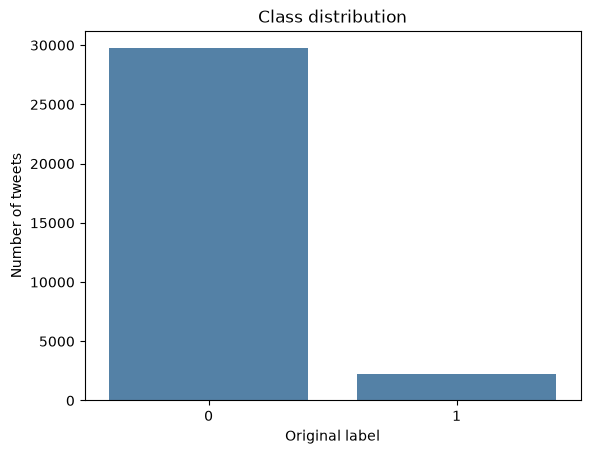

In [4]:
ax = sns.countplot(data=tweets_df, x="label", color="steelblue")
ax.set_title("Class distribution")
ax.set_xlabel("Original label")
ax.set_ylabel("Number of tweets")
plt.show()

### Interpretation

The supplied file contains 31,962 rows, with 29,720 label-0 records and 2,242 label-1 records. There are 2,432 repeated tweet texts (but no exact duplicate full rows), and the repeated texts have consistent labels in this file. The minority class is only about 7% of the data.

Repeated tweet text can leak across a random train/test split. The workflow below therefore checks for conflicting labels and removes exact repeated tweet texts before splitting. This leaves 29,530 unique tweet texts. The CSV itself does not contain a textual label dictionary, so verify the meaning of `0` and `1` from the original dataset documentation.

## 4. Prepare the text

The cleaning function below:
- lowercases text;
- removes URLs and `@mentions`;
- removes the `#` symbol but keeps the hashtag word;
- removes punctuation and extra whitespace.

Stopword removal is handled by `CountVectorizer`. Negation terms are deliberately retained because they can change meaning.

In [5]:
# Remove negation words from scikit-learn's English stopword list.
negation_words = {"no", "not", "nor", "never", "none", "cannot"}
custom_stop_words = sorted(set(ENGLISH_STOP_WORDS) - negation_words)

def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)  # URLs
    text = re.sub(r"@\w+", " ", text)                       # user mentions
    text = text.replace("#", "")                              # keep hashtag text
    text = re.sub(r"[^a-z0-9\s]", " ", text)                # punctuation/symbols
    text = re.sub(r"\s+", " ", text).strip()
    return text

example = tweets_df["tweet"].iloc[0]
print("Original:", example)
print("Cleaned: ", clean_tweet(example))

Original:  @user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction.   #run
Cleaned:  when a father is dysfunctional and is so selfish he drags his kids into his dysfunction run


The workflow removes repeated exact tweet texts before splitting, so an identical tweet cannot appear in both train and test sets. It checks that duplicate tweet strings do not have conflicting labels. `stratify=y` preserves approximately the same class proportions in both sets. `random_state` makes the split reproducible.

We drop `id` because it is an identifier, not tweet content. The vectorizer is still fitted only on the training text.

In [6]:
required_columns = {"label", "tweet"}
missing_columns = required_columns - set(tweets_df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

tweets_df = tweets_df.dropna(subset=["label", "tweet"]).copy()
tweets_df["label"] = tweets_df["label"].astype(int)

# Check whether identical tweet text has contradictory labels.
label_counts_per_tweet = tweets_df.groupby("tweet")["label"].nunique()
conflicting_tweets = int((label_counts_per_tweet > 1).sum())
print("Tweet texts with conflicting labels:", conflicting_tweets)

if conflicting_tweets:
    raise ValueError("Resolve duplicate tweet texts with conflicting labels before splitting.")

# Remove exact repeated tweet texts to prevent train/test leakage.
tweets_df = tweets_df.drop_duplicates(subset="tweet", keep="first").copy()
print("Rows after removing repeated tweet texts:", len(tweets_df))

X_text = tweets_df["tweet"].astype(str)
y = tweets_df["label"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train_text))
print("Test rows:", len(X_test_text))
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index())
print("\nTest class proportions:")
display(y_test.value_counts(normalize=True).sort_index())

Tweet texts with conflicting labels: 0
Rows after removing repeated tweet texts: 29530
Training rows: 23624
Test rows: 5906

Training class proportions:


label
0    0.931849
1    0.068151
Name: proportion, dtype: float64


Test class proportions:


label
0    0.931764
1    0.068236
Name: proportion, dtype: float64

## 6. Convert tweets into numeric features

`CountVectorizer` learns its vocabulary from the training set only. Unigrams and bigrams allow the model to use individual words and two-word phrases. `min_df=2` removes tokens that appear only once in the training data, reducing noise.

The matrices remain sparse. Do not convert them to a dense pandas DataFrame with `.toarray()`; that wastes memory for text data.

In [7]:
vectorizer = CountVectorizer(
    preprocessor=clean_tweet,
    stop_words=custom_stop_words,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    dtype=np.int32
)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Training matrix:", X_train.shape)
print("Test matrix:", X_test.shape)
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))

Training matrix: (23624, 25471)
Test matrix: (5906, 25471)
Vocabulary size: 25471


## 7. Establish a majority-class baseline

A baseline predicts the most frequent training label for every tweet. A useful model should do better than this baseline, especially on the minority class.

In [8]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_predictions), 4))
print("Baseline balanced accuracy:", round(balanced_accuracy_score(y_test, baseline_predictions), 4))
print(classification_report(y_test, baseline_predictions, zero_division=0))

Baseline accuracy: 0.9318
Baseline balanced accuracy: 0.5
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      5503
           1       0.00      0.00      0.00       403

    accuracy                           0.93      5906
   macro avg       0.47      0.50      0.48      5906
weighted avg       0.87      0.93      0.90      5906



## 8. Train the Multinomial Naive Bayes classifier

`alpha` controls additive (Laplace/Lidstone) smoothing. The value below is a reasonable starting point, not a guaranteed optimum. It should be tuned using cross-validation on the training data only if further optimization is required.

In [9]:
nb_classifier = MultinomialNB(alpha=0.5)
nb_classifier.fit(X_train, y_train)

y_pred = nb_classifier.predict(X_test)

## 9. Evaluate the model

For this imbalanced problem, inspect the label-1 precision, recall, and F1-score instead of relying on accuracy alone.

- **Precision:** Of the tweets predicted as label 1, how many truly belong to label 1?
- **Recall:** Of all true label-1 tweets, how many did the model find?
- **F1-score:** Harmonic mean of precision and recall.
- **Balanced accuracy:** Average recall across classes.

In [10]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

Accuracy: 0.9617
Balanced accuracy: 0.8208

Classification report:
              precision    recall  f1-score   support

           0     0.9751    0.9840    0.9796      5503
           1     0.7507    0.6576    0.7011       403

    accuracy                         0.9617      5906
   macro avg     0.8629    0.8208    0.8403      5906
weighted avg     0.9598    0.9617    0.9606      5906



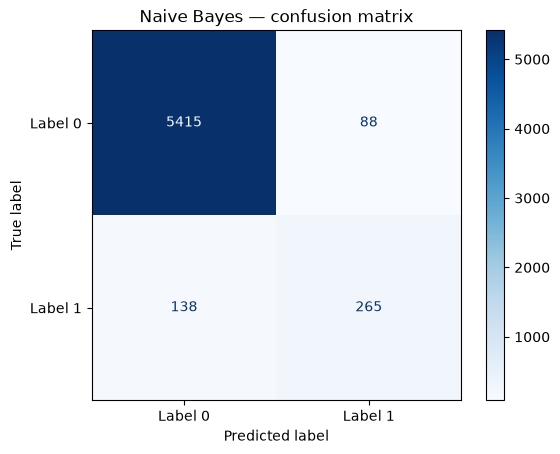

Confusion matrix layout: rows = actual labels; columns = predicted labels.


In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Label 0", "Label 1"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Naive Bayes — confusion matrix")
plt.show()

print("Confusion matrix layout: rows = actual labels; columns = predicted labels.")

## 10. Interpret the Naive Bayes model

Naive Bayes does not learn logistic-regression coefficients. Instead, `feature_log_prob_` contains the log probability of each token given each class.

The difference below is:

`log P(token | class 1) - log P(token | class 0)`

- Positive values indicate a token is more associated with class 1 in the training data.
- Negative values indicate a token is more associated with class 0.
- These are **descriptive model associations**, not causal effects or proof that a word is inherently harmful.

Because tokens can be correlated and the model uses smoothed word counts, interpret the rankings cautiously.

In [12]:
feature_names = vectorizer.get_feature_names_out()
class_to_row = {label: row for row, label in enumerate(nb_classifier.classes_)}

log_prob_0 = nb_classifier.feature_log_prob_[class_to_row[0]]
log_prob_1 = nb_classifier.feature_log_prob_[class_to_row[1]]
log_probability_difference = log_prob_1 - log_prob_0

feature_analysis = pd.DataFrame({
    "token": feature_names,
    "log_probability_class_0": log_prob_0,
    "log_probability_class_1": log_prob_1,
    "log_probability_difference_1_minus_0": log_probability_difference,
    "absolute_difference": np.abs(log_probability_difference)
})

top_class_1 = feature_analysis.nlargest(20, "log_probability_difference_1_minus_0")
top_class_0 = feature_analysis.nsmallest(20, "log_probability_difference_1_minus_0")

print("Tokens most associated with label 1:")
display(top_class_1[["token", "log_probability_difference_1_minus_0"]])

print("Tokens most associated with label 0:")
display(top_class_0[["token", "log_probability_difference_1_minus_0"]])

Tokens most associated with label 1:


,token,log_probability_difference_1_minus_0
963,allahsoil,6.952262
16779,paladino,5.880142
6809,emiratis,5.611878
22067,teambts,5.559234
16152,notmypresident,5.315612
1027,altright,5.244153
3664,carl paladino,5.244153
5212,daily thanks,5.244153
13196,listen retweet,5.244153
245,2016in4words,5.167192


Tokens most associated with label 0:


,token,log_probability_difference_1_minus_0
2565,bihday,-5.255833
24515,weekend,-4.936171
8609,fun,-4.909198
8413,friday,-4.802786
21587,summer,-4.791021
22259,thankful,-4.788651
22885,tomorrow,-4.637856
7591,father day,-4.584018
5102,cute,-4.486231
9939,happiness,-4.453601


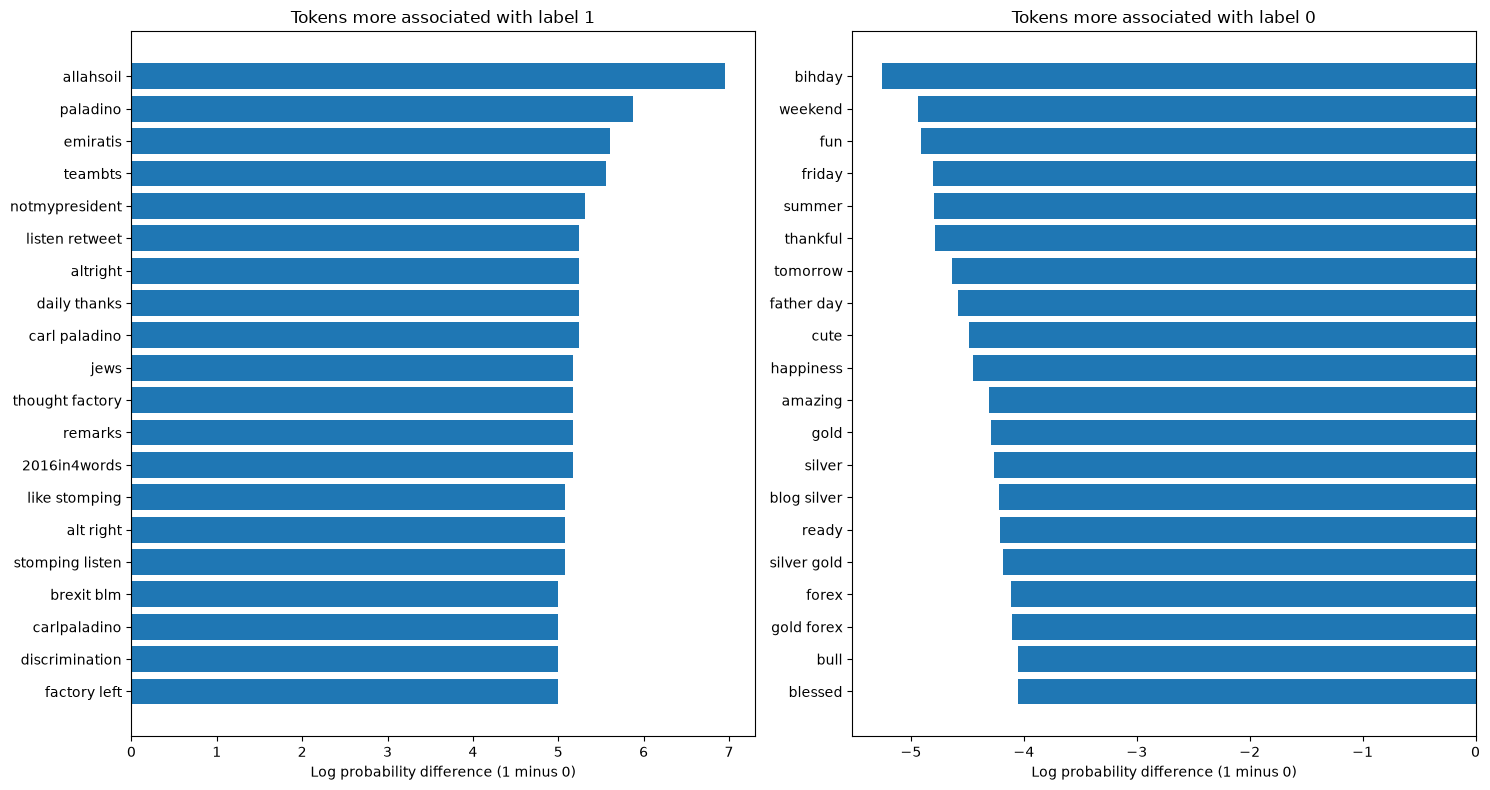

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

plot_1 = top_class_1.sort_values("log_probability_difference_1_minus_0")
axes[0].barh(plot_1["token"], plot_1["log_probability_difference_1_minus_0"])
axes[0].set_title("Tokens more associated with label 1")
axes[0].set_xlabel("Log probability difference (1 minus 0)")

plot_0 = top_class_0.sort_values("log_probability_difference_1_minus_0", ascending=False)
axes[1].barh(plot_0["token"], plot_0["log_probability_difference_1_minus_0"])
axes[1].set_title("Tokens more associated with label 0")
axes[1].set_xlabel("Log probability difference (1 minus 0)")

plt.tight_layout()
plt.show()

## 11. Review misclassified examples

Inspect false negatives and false positives. This can reveal ambiguous labels, sarcasm, context dependence, spelling variations, and weaknesses in preprocessing. Do not publish example tweets containing personal information without considering privacy.

In [14]:
error_review = pd.DataFrame({
    "tweet": X_test_text.reset_index(drop=True),
    "actual_label": y_test.reset_index(drop=True),
    "predicted_label": y_pred
})
errors = error_review[error_review["actual_label"] != error_review["predicted_label"]]
display(errors.head(20))
print("Total misclassified examples:", len(errors))

,tweet,actual_label,predicted_label
19,dear @user you are a asshole. please go fuck ...,1,0
27,racism won't cease. white priviledge must be b...,1,0
110,#cnn is now as bad as #msnbc...down playing th...,0,1
113,i keep my opinions to myself because people te...,0,1
138,"reason #638 on why i don't suppo modern day ""f...",0,1
141,@user #trumpuniversity video leaked #neverump ...,0,1
165,#itwing to play impoant role in 2017 polls: ...,0,1
176,@user all the criticism comes from fox news th...,0,1
243,every lactation consultant i've ever met has b...,1,0
280,"@user imagine that, @user is finally ashamed e...",1,0


Total misclassified examples: 226


With the supplied CSV and the settings in this notebook (exact duplicate tweet texts removed before splitting; 80/20 stratified split; random state 42; CountVectorizer unigrams+bigrams; `min_df=2`; `max_df=0.98`; and `MultinomialNB(alpha=0.5)`), the test results were:

| Metric | Result |
|---|---:|
| Accuracy | 0.9617 |
| Balanced accuracy | 0.8208 |
| Label 1 precision | 0.7507 |
| Label 1 recall | 0.6576 |
| Label 1 F1-score | 0.7011 |

Confusion matrix (actual rows, predicted columns):

| | Predicted 0 | Predicted 1 |
|---|---:|---:|
| Actual 0 | 5,415 | 88 |
| Actual 1 | 138 | 265 |

These results are for one reproducible holdout split, not a guarantee of future performance. The model misses 138 of the 403 label-1 test examples, so minority-class recall still needs improvement if missing such content is costly.

## 13. Recommendations and limitations

1. **Verify the label definition.** The CSV does not explain what `0` and `1` mean. Cite the correct dataset documentation and avoid calling the task positive/negative sentiment unless the source explicitly defines it that way.
2. **Address class imbalance.** Compare class weighting or resampling methods, but apply them only to training data. For Naive Bayes, do not assume SMOTE is automatically appropriate for sparse word-count features.
3. **Tune for the real objective.** Use stratified cross-validation on the training set and select a metric such as label-1 F1 or recall based on the costs of false positives and false negatives.
4. **Compare models.** Try Complement Naive Bayes and Logistic Regression with TF-IDF. Logistic Regression will provide actual coefficients; Naive Bayes uses conditional token probabilities.
5. **Try TF-IDF and character n-grams.** They may help with repeated words, misspellings, and variations, but compare them on held-out data.
6. **Inspect errors and possible label noise.** Tweet meaning often depends on context, irony, reclaimed language, and conversational history that a bag-of-words model cannot understand.
7. **Avoid overstating the model.** This is a baseline text classifier, not a reliable automated moderation system. Test on newer and independently collected data before any real-world use.

### Final assessment

The original notebook was a useful introduction to text classification, but its evaluation needed a reproducible stratified split, a baseline, minority-class metrics, and a careful interpretation of the labels. The revised notebook addresses those points and keeps the model's limitations visible.